# How to read negative loadings

MVSA archetypes can have negative loadings, and notebook 13 found them in every
year. Notebook 14 settled which normalizations keep the linear mixing model
(LMM) exact. This notebook asks what a negative loading *means*, and when the
data force one.

1. **Archetypes as an affine basis.** Each precinct is a combination of the
   archetypes with weights (abundances) that sum to one. A negative loading is
   then a correction term: in precincts with that archetype, the candidate gets
   fewer votes than the other archetypes present would give. Three caveats:
   - its net effect is a contrast with whatever it replaces;
   - the basis is not unique, so the sign is relative to this fit;
   - no precinct can be purely that archetype.
2. **When negative loadings are forced.** The smallest simplex around the data
   has to overshoot whenever the data have more corners than there are
   archetypes. Where the data press against zero votes for some candidates, that
   overshoot produces negative loadings. Three election mechanisms do this:
   - two independent choices;
   - ballot width that varies independently of the political mix;
   - more voter types than archetypes.

   Noise adds small ones. Proportional undervoting does not.
3. **Toy cases**, one per mechanism, with the signature each leaves.
4. **NMF as a basis.** All loadings are nonnegative, so there are no correction
   terms. What this does to "mixing": NMF and MVSA put the mixing in different
   factors. NMF's precincts are purer, but its archetypes are blends of MVSA's,
   closer together and nearly unchanged from one $p$ to the next. The contrast
   in the votes is reduced only where the data press against zero.
5. **The real archetypes**, sorted by those signatures and compared with NMF.

Notation follows notebook 14 and the MVSA paper (Li and Bioucas-Dias 2008):
$\mathbf Y = \mathbf M \mathbf S$, $\mathbf S \succeq 0$,
$\mathbf 1_p^\top \mathbf S = \mathbf 1_n^\top$; candidates
$\ell = 1, \dots, L$, archetypes $i, k = 1, \dots, p$, precincts
$j = 1, \dots, n$. Units are given for per-ballot normalization: loadings and
votes in votes/ballot, abundances in ballots/ballot. Under vote-sum both become
votes/vote (notebook 14, Table of units).

## 1. Archetypes as an affine basis

**Coordinates.** The LMM writes each precinct as

$$
\underbrace{\mathbf y_j}_{\text{votes/ballot}} = \sum_{i=1}^{p} \underbrace{[\mathbf S]_{ij}}_{\text{ballots/ballot}}\ \underbrace{\mathbf m_i}_{\text{votes/ballot}},
\qquad \sum_{i=1}^p [\mathbf S]_{ij} = 1,
\tag{1}
$$

or, in one equation,

$$
\begin{bmatrix} \mathbf y_j \\ 1 \end{bmatrix} =
\begin{bmatrix} \mathbf M \\ \mathbf 1_p^\top \end{bmatrix} \mathbf s_j .
\tag{2}
$$

If the archetypes are affinely independent ($[\mathbf M;\, \mathbf 1_p^\top]$ has
rank $p$), then (2) has exactly one solution,
$\mathbf s_j = [\mathbf M;\, \mathbf 1_p^\top]^{+} [\mathbf y_j;\, 1]$. So the
archetypes are an *affine basis* for the plane the data lie in, and a precinct's
abundances are its (barycentric) coordinates in that basis. The loading vectors
$\mathbf m_i$ are not necessarily orthogonal. The coordinates come from solving
(2), not from projecting $\mathbf y_j$ onto each $\mathbf m_i$.

**Positive contributions and corrections.** For candidate $\ell$, split the
archetypes by the sign of their loading,
$P_\ell = \{i : [\mathbf M]_{\ell i} \ge 0\}$ and
$N_\ell = \{i : [\mathbf M]_{\ell i} < 0\}$. Then

$$
\underbrace{[\mathbf y_j]_\ell}_{\text{votes/ballot}} =
\underbrace{\sum_{i \in P_\ell} [\mathbf S]_{ij} [\mathbf M]_{\ell i}}_{\text{positive contributions}}
\; - \;
\underbrace{\sum_{i \in N_\ell} [\mathbf S]_{ij}\, \big|[\mathbf M]_{\ell i}\big|}_{\text{correction}} .
\tag{3}
$$

Every precinct has $[\mathbf y_j]_\ell \ge 0$, so in an exact fit the
correction never exceeds the positive contributions. An archetype with a
negative loading for $\ell$ only ever lowers $\ell$'s votes below what the other
archetypes in the precinct would give.

In what follows, fix an archetype $k$ and a precinct $j$ and write
$s_i := [\mathbf S]_{ij}$.

**Proposition 1 (a precinct is the rest of its mix plus archetype $k$).** For
$s_k < 1$, let

$$
\bar{\mathbf y}_{-k,j} := \frac{1}{1 - s_k} \sum_{i \ne k} s_i\, \mathbf m_i
$$

be the precinct's profile without archetype $k$ (the other archetypes in their
own proportions). Then

$$
\mathbf y_j = (1 - s_k)\, \bar{\mathbf y}_{-k,j} + s_k\, \mathbf m_k .
\tag{4}
$$

Moving $\delta$ of the precinct's abundance into $k$, taken from the other
archetypes in proportion, changes candidate $\ell$'s votes by

$$
\underbrace{\Delta [\mathbf y_j]_\ell}_{\text{votes/ballot}} =
\underbrace{\delta}_{\text{ballots/ballot}}\,
\big(\underbrace{[\mathbf M]_{\ell k} - [\bar{\mathbf y}_{-k,j}]_\ell}_{\text{votes/ballot}}\big).
\tag{5}
$$

Taking $\delta$ from a single archetype $r$ instead gives
$\Delta [\mathbf y_j]_\ell = \delta\,([\mathbf M]_{\ell k} - [\mathbf M]_{\ell r})$.

*Proof.* (4) is (1) with the $i = k$ term separated. After the move, the other
archetypes keep their proportions, so $\bar{\mathbf y}_{-k,j}$ is unchanged and
$\mathbf y_j' = (1 - s_k - \delta)\bar{\mathbf y}_{-k,j} + (s_k + \delta)\mathbf m_k$,
which differs from (4) by $\delta(\mathbf m_k - \bar{\mathbf y}_{-k,j})$. For a
single donor $r$, $\mathbf y_j$ depends on $s_k$ and $s_r$ only through
$s_k \mathbf m_k + s_r \mathbf m_r$, which changes by
$\delta(\mathbf m_k - \mathbf m_r)$. $\square$

So the effect of a negative loading is a *contrast* with what it replaces. With
$[\mathbf M]_{\ell k} = -0.5$ and the rest of the precinct giving $\ell$ 0.4
votes per ballot, each 0.1 of abundance moved into $k$ costs $\ell$ 0.09 votes
per ballot, not 0.05.

**Proposition 2 (the basis is not unique).** Let $\mathbf Y = \mathbf M \mathbf S$
be exact with $\mathbf S \succeq 0$ and $\mathbf 1_p^\top \mathbf S = \mathbf 1_n^\top$.
For any invertible $\mathbf T \in \mathbb R^{p \times p}$ with
$\mathbf 1_p^\top \mathbf T = \mathbf 1_p^\top$ and
$\mathbf T^{-1}\mathbf S \succeq 0$, the pair
$(\mathbf M', \mathbf S') = (\mathbf M \mathbf T, \mathbf T^{-1}\mathbf S)$ is also
an exact fit. Each new archetype $\mathbf m'_k = \sum_i [\mathbf T]_{ik} \mathbf m_i$
is an *affine* combination of the old ones: its weights sum to one but may be
negative.

*Proof.* $\mathbf M'\mathbf S' = \mathbf M\mathbf S = \mathbf Y$. Multiplying
$\mathbf 1_p^\top \mathbf T = \mathbf 1_p^\top$ on the right by $\mathbf T^{-1}$
gives $\mathbf 1_p^\top \mathbf T^{-1} = \mathbf 1_p^\top$, so
$\mathbf 1_p^\top \mathbf S' = \mathbf 1_p^\top \mathbf S = \mathbf 1_n^\top$.
$\mathbf S' \succeq 0$ by assumption, and the columns of $\mathbf T$ sum to one.
$\square$

*Example.* Push a vertex past type $a$, away from type $b$:
$\mathbf m' = (1+\alpha)\mathbf m_a - \alpha\, \mathbf m_b$ with $\alpha > 0$. Its
loading on $\ell$ is
$[\mathbf m']_\ell = [\mathbf m_a]_\ell + \alpha([\mathbf m_a]_\ell - [\mathbf m_b]_\ell)$,
which is negative exactly when $[\mathbf m_b]_\ell > [\mathbf m_a]_\ell$ and
$\alpha > [\mathbf m_a]_\ell / ([\mathbf m_b]_\ell - [\mathbf m_a]_\ell)$. So a
negative loading on $\ell$ marks an archetype pushed away from the types that
support $\ell$.

Which basis we get is a choice. MVSA picks the smallest simplex volume, NMF a
nonnegative one. A negative loading describes archetype $k$ *relative to the
other archetypes of this fit*.

**Proposition 3 (a negative loading caps the abundance).** In an exact fit, if
$[\mathbf M]_{\ell k} < 0$, then every precinct with
$[\bar{\mathbf y}_{-k,j}]_\ell > 0$ satisfies

$$
s_k \;\le\; \frac{[\bar{\mathbf y}_{-k,j}]_\ell}{[\bar{\mathbf y}_{-k,j}]_\ell - [\mathbf M]_{\ell k}} \;<\; 1,
\tag{6}
$$

so no precinct is purely archetype $k$. Summing (4) over candidates, with the
column sum $c_k = \mathbf 1_L^\top \mathbf m_k$, the width
$w_j = \mathbf 1_L^\top \mathbf y_j$ and
$\bar w_{-k,j} = \mathbf 1_L^\top \bar{\mathbf y}_{-k,j}$ (all in votes/ballot),

$$
\underbrace{c_k}_{\text{votes/ballot}} \;=\; \bar w_{-k,j} - \frac{\bar w_{-k,j} - w_j}{s_k} .
\tag{7}
$$

*Proof.* By (4), $[\mathbf y_j]_\ell \ge 0$ reads
$(1 - s_k)[\bar{\mathbf y}_{-k,j}]_\ell + s_k [\mathbf M]_{\ell k} \ge 0$, i.e.
$s_k([\bar{\mathbf y}_{-k,j}]_\ell - [\mathbf M]_{\ell k}) \le [\bar{\mathbf y}_{-k,j}]_\ell$.
Applying $\mathbf 1_L^\top$ to (4) gives
$w_j = (1 - s_k)\bar w_{-k,j} + s_k c_k$; solve for $c_k$. $\square$

The more negative the loading, the smaller the share of any precinct the
archetype can take. By (7), a column sum below zero means the archetype accounts
for precincts whose width falls short of the rest of their mix
($\bar w_{-k,j} - w_j > 0$) by more than $s_k \bar w_{-k,j}$. The shortfall is
spread thinly over small abundances, so the vertex lies far beyond every
precinct. The **extrapolation factor** $1 / \max_j [\mathbf S]_{kj}$ measures
how far.

> **Reading a negative loading.**
> - *It's a correction.* In precincts with archetype $k$, candidate $\ell$ gets
>   fewer votes than the other archetypes present would give (3).
> - *Its effect is a contrast* with what it replaces (Proposition 1).
> - *It's relative to this fit*, and the archetype is a direction, not a group
>   of voters: no precinct is purely $k$ (Propositions 2 and 3).

## 2. When are negative loadings forced?

Let $D = \operatorname{conv}\{\mathbf y_1, \dots, \mathbf y_n\}$ be the data
polytope, $A = \operatorname{aff} D$ its plane (dimension $p - 1$ for a
$p$-archetype fit), and $P = A \cap \mathbb R^L_{\ge 0}$ the nonnegative part of
that plane. Every precinct lies in $P$.

**Lemma 4 (overshoot).** If $D$ is not a simplex, every $(p-1)$-simplex that
contains $D$ has a vertex outside $D$.

*Proof.* If every vertex were in $D$, the simplex would lie in $D$ ($D$ is
convex) and contain it, so it would equal $D$. $\square$

**Corollary 5 (forced negative loadings).** If moreover $D = P$, every exact
$p$-archetype fit has a negative loading. This holds for MVSA, NMF with the
sum-to-one constraint, or any other method.

*Proof.* The archetypes are affinely independent and their plane contains $D$,
so it contains $A$. Both have dimension $p - 1$, so the archetypes lie in $A$.
By Lemma 4 one of them lies outside $D = P$: it is in $A$ but not in
$\mathbb R^L_{\ge 0}$, so it has a negative entry. $\square$

When $D \ne P$, negative loadings can be avoided exactly when some simplex fits
between $D$ and $P$. This is the nested-polytope problem behind exact NMF
(Vavasis 2009; Gillis and Glineur 2012). MVSA does not look for such a simplex.
It takes the smallest one, which crosses the orthant wherever $D$ presses
against the boundary of $P$, i.e. wherever some precincts give a candidate
almost no votes.

$D$ has more corners than there are archetypes in three ways that matter for
elections:

- **(a) Two independent choices.** Voters choose between candidates A1 and A2
  and, independently, between B1 and B2. The data then form a square (4
  corners) in a plane ($p = 3$). If precincts reach all four combinations, then
  $D = P$ and Corollary 5 forces negative loadings.
- **(b) Ballot width independent of the political mix.** Each precinct loses
  $d_j$ names per ballot, with lost marks distributed by a fixed profile
  $\mathbf f \succeq 0$, $\mathbf 1_L^\top \mathbf f = 1$:
  $$
  \mathbf y_j = \mathbf M \mathbf s_j - d_j\, \mathbf f,
  \qquad d_j \in [0, d_{\max}] .
  $$
  With $q$ political types, $D$ is a prism (simplex $\times$ segment): $2q$
  corners in $q$ dimensions, fit by $q + 1$ archetypes. Since $2q > q + 1$ for
  $q \ge 2$, the fit overshoots. Either one archetype goes past the low-width
  face (below zero names per ballot), or the slates go past the full-width face
  (more names than any precinct has), or both.
- **(c) More voter types than archetypes.** $D$ has more than $p$ corners in the
  $(p-1)$-dimensional space the fit lives in.

Sampling noise adds a fourth, milder cause. It scatters precincts outside the
noise-free $D$, so the enclosing simplex grows slightly. That gives small
negative loadings where the true loadings are near zero (notebook 14's
vote-sum toy, $-7\%$).

**Proposition 6 (proportional undervoting does not force negatives).** Suppose
each voter marks each candidate with their type's probability scaled by a
precinct factor $\lambda_j \in (0, 1]$, i.e.
$\mathbf y_j = \lambda_j \mathbf M \mathbf s_j$. Then

$$
\mathbf y_j = \begin{bmatrix} \mathbf M & \mathbf 0 \end{bmatrix}
\begin{bmatrix} \lambda_j \mathbf s_j \\ 1 - \lambda_j \end{bmatrix},
$$

an exact LMM with $p + 1$ nonnegative archetypes, one of them the blank ballot
at the origin.

*Proof.* The abundances are nonnegative and sum to
$\lambda_j \mathbf 1_p^\top \mathbf s_j + 1 - \lambda_j = 1$. $\square$

So losing a *fraction* of each voter's marks costs one archetype at the origin,
with a column sum of zero and no negative loadings. Losing a fixed *number* of
names regardless of the mix is mechanism (b), which overshoots.

## 3. Toy cases

One case per mechanism, plus a control. Unless noted, counts are binomial,
$[\mathbf V]_{\ell j} \sim \mathrm{Binomial}(B_j, [\mathbf E]_{\ell j})$ with
$B_j \sim \mathrm{Unif}\{200, \dots, 799\}$ and expected names per ballot
$\mathbf E$, divided by $B_j$ (per-ballot normalization). The fit is the
pipeline's MVSA (`extract_endmembers`, best of 5 seeds by RMSE) with SUNSAL
abundances. Twelve candidates throughout.

| case | mechanism | true structure | fit |
|---|---|---|---|
| C0 | control | 3 types, near-pure precincts exist | $p = 3$ |
| C1 | noise | C0 with $B_j = 30$ | $p = 3$ |
| C2 | proportional undervoting (Proposition 6) | C0 $\times\ \lambda_j \sim \mathrm{Unif}[0.35, 1]$ | $p = 4$ |
| C3 | width independent of mix, (b) | 3 well-mixed types, minus $d_j \mathbf f$ with $\mathbf f$ $\propto$ popularity | $p = 4$ |
| C4 | more types than archetypes, (c) | 4 types | $p = 3$ |
| C5 | two independent choices, (a) | square, noise-free | $p = 3$ |

Run time: about a minute.

In [1]:
import sys
import warnings

sys.path.append("..")

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment
from scipy.stats import spearmanr

from src.unmixing import extract_endmembers, sunsal_mod

# VCA prints these on every run; they do not affect the result
warnings.filterwarnings("ignore", message="sparse_svds failed")
warnings.filterwarnings("ignore", message="SNR estimation")

# dataviz reference palette: categorical slots in fixed order, ink, grid
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
mpl.rcParams.update({
    "font.size": 8.5, "axes.titlesize": 9, "axes.labelsize": 8.5,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "figure.dpi": 120,
})

L, n = 12, 4000
rng = np.random.default_rng(1)
B = rng.integers(200, 800, n)


def binom(E, ballots=B):
    """Per-ballot vote shares from binomial counts with expected rates E (L, n)."""
    return rng.binomial(np.broadcast_to(ballots, E.shape), np.clip(E, 0, 1)) / ballots


def mvsa_fit(Y, p, seeds=5):
    """Best-of-seeds MVSA + SUNSAL (non-negative, sum-to-one): (rmse, M_hat, S_hat)."""
    best = None
    for seed in range(seeds):
        M_hat = extract_endmembers(Y, p, seed, "mvsa", {"MM_iters": 10})
        S_hat, _, _ = sunsal_mod(M_hat, Y, positivity="yes", addone="yes",
                                 AL_iters=2000, tol=1e-7)
        rmse = np.sqrt(np.mean((Y - M_hat @ S_hat) ** 2))
        if best is None or rmse < best[0]:
            best = (rmse, M_hat, S_hat)
    return best

In [2]:
# Voter types: [M]_{li} = chance a type-i voter marks candidate l (votes/ballot)
M3 = np.full((L, 3), 0.05)
M3[[0, 1, 2, 3, 4, 5, 6, 7], 0] = [0.85, 0.80, 0.75, 0.70, 0.65, 0.60, 0.55, 0.50]
M3[[3, 4, 8, 9, 10, 2], 1] = [0.50, 0.45, 0.90, 0.60, 0.55, 0.40]
M3[[5, 6, 10, 11], 2] = [0.35, 0.30, 0.40, 0.80]
M4 = np.column_stack([M3, np.full(L, 0.05)])           # C4: a fourth type
M4[[0, 1, 2, 7, 9, 11], 3] = [0.10, 0.70, 0.60, 0.90, 0.80, 0.10]
Ms = np.full((L, 3), 0.20)                             # C3: slates over a 0.2 floor
Ms[[0, 1, 2, 3, 4, 5, 6, 7], 0] = [0.90, 0.85, 0.80, 0.80, 0.75, 0.70, 0.70, 0.65]
Ms[[2, 3, 4, 8, 9, 10, 11, 6], 1] = [0.60, 0.70, 0.65, 0.90, 0.85, 0.80, 0.75, 0.50]
Ms[[0, 5, 6, 9, 10, 11, 1, 8], 2] = [0.30, 0.80, 0.85, 0.40, 0.90, 0.85, 0.50, 0.60]

CASES = {}
S3 = rng.dirichlet([0.5] * 3, n).T                     # near-pure precincts exist

CASES["C0"] = dict(label="control", Y=binom(M3 @ S3), M=M3, p=3)
CASES["C1"] = dict(label="noise (B = 30)", Y=binom(M3 @ S3, np.full(n, 30)), M=M3, p=3)

lam = rng.uniform(0.35, 1, n)
CASES["C2"] = dict(label="proportional undervoting", Y=binom(lam * (M3 @ S3)),
                   M=np.column_stack([M3, np.zeros(L)]), p=4)

# C3: lost marks follow national popularity; d_j capped so no rate goes negative
Smix = rng.dirichlet([3.0] * 3, n).T                   # well mixed, no pure precincts
E = Ms @ Smix
f = Ms.mean(axis=1) / Ms.mean(axis=1).sum()
d = rng.uniform(0, 0.98 * (E / f[:, None]).min(), n)
CASES["C3"] = dict(label="width independent of mix", Y=binom(E - f[:, None] * d), M=Ms, p=4)

S4 = rng.dirichlet([0.5] * 4, n).T
CASES["C4"] = dict(label="4 types, 3 archetypes", Y=binom(M4 @ S4), M=M4, p=3)

# C5: two independent binary choices; candidates 1/2 and 3/4 split, the rest fixed
a, b = rng.uniform(0, 1, n), rng.uniform(0, 1, n)
Y5 = np.full((L, n), 0.30)
Y5[0], Y5[1], Y5[2], Y5[3] = 0.9 * a, 0.9 * (1 - a), 0.8 * b, 0.8 * (1 - b)
corners = np.array([[a_, b_] for a_ in (0, 1) for b_ in (0, 1)])
M5 = np.full((L, 4), 0.30)
M5[0], M5[1], M5[2], M5[3] = 0.9 * corners[:, 0], 0.9 * (1 - corners[:, 0]), \
    0.8 * corners[:, 1], 0.8 * (1 - corners[:, 1])
CASES["C5"] = dict(label="two independent choices", Y=Y5, M=M5, p=3)

for key, c in CASES.items():
    c["rmse"], c["M_hat"], c["S_hat"] = mvsa_fit(c["Y"], c["p"])
print("done")

done


### Field guide

Per case:
- **negative loadings:** count below $-1\%$ of the largest true loading, and the
  most negative loading;
- **column sums** of the fitted and the true archetypes (names per ballot);
- **largest abundance** of the archetype with the most negative loading,
  $\max_j [\hat{\mathbf S}]_{kj}$, and its extrapolation factor $1/\max$
  (Proposition 3);
- **width correlation:** Spearman correlation of that archetype's abundance
  with the precinct width $w_j$.

In [3]:
rows = []
for key, c in CASES.items():
    M_hat, S_hat, Y = c["M_hat"], c["S_hat"], c["Y"]
    k = int(np.unravel_index(np.argmin(M_hat), M_hat.shape)[1])  # holds the min loading
    w = Y.sum(axis=0)
    rho = spearmanr(S_hat[k], w)[0] if w.std() > 1e-9 else np.nan
    rows.append({
        "case": key,
        "mechanism": c["label"],
        "p": c["p"],
        "RMSE": c["rmse"],
        "# negative": int((M_hat < -0.01 * c["M"].max()).sum()),
        "min loading": M_hat.min(),
        "fitted column sums": " / ".join(f"{v:.2f}" for v in M_hat.sum(axis=0)),
        "true column sums": " / ".join(f"{v:.2f}" for v in c["M"].sum(axis=0)),
        "max abundance of k": S_hat[k].max(),
        "extrapolation 1/max": 1 / S_hat[k].max(),
        "Spearman(s_k, width)": rho,
    })
guide = pd.DataFrame(rows).set_index("case")
guide.round(3)

,mechanism,p,RMSE,# negative,min loading,fitted column sums,true column sums,max abundance of k,extrapolation 1/max,"Spearman(s_k, width)"
case,,,,,,,,,,
C0,control,3,0.019,0,0.005,2.12 / 5.72 / 3.69,5.60 / 3.70 / 2.25,0.957,1.045,-0.805
C1,noise (B = 30),3,0.071,13,-0.097,1.87 / 3.68 / 6.38,5.60 / 3.70 / 2.25,0.837,1.194,0.873
C2,proportional undervoting,4,0.016,12,-0.042,2.32 / 3.80 / -0.33 / 6.14,5.60 / 3.70 / 2.25 / 0.00,0.663,1.509,-0.779
C3,width independent of mix,4,0.020,13,-0.457,4.20 / 11.13 / 2.41 / 3.23,6.95 / 6.55 / 6.00,0.610,1.639,-0.460
C4,"4 types, 3 archetypes",3,0.089,10,-0.367,5.66 / 3.76 / 1.82,5.60 / 3.70 / 2.25 / 3.50,0.706,1.416,-0.703
C5,two independent choices,3,0.000,4,-0.814,4.10 / 4.10 / 4.10,4.10 / 4.10 / 4.10 / 4.10,0.568,1.762,NaN


### The archetype with the most negative loading, per case

Filled stems are the fitted loadings. Open circles are the true type closest to
it by cosine (none for the C2 blank-ballot direction, whose true profile is the
origin).

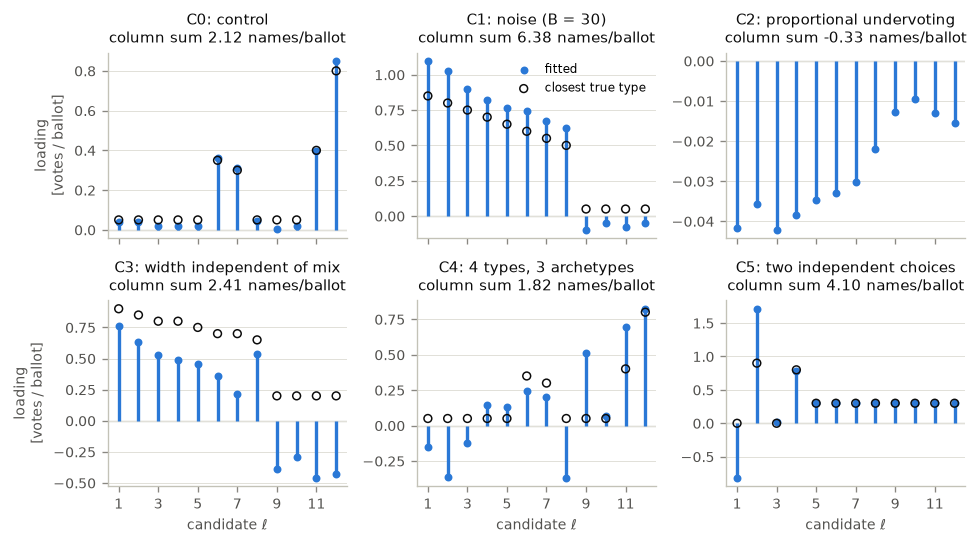

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(8.2, 4.6), sharex=True)
x = np.arange(1, L + 1)
for ax, (key, c) in zip(axes.flat, CASES.items()):
    M_hat = c["M_hat"]
    k = int(np.unravel_index(np.argmin(M_hat), M_hat.shape)[1])
    m = M_hat[:, k]
    T = c["M"]
    nz = np.linalg.norm(T, axis=0) > 0
    cos = (T[:, nz] / np.linalg.norm(T[:, nz], axis=0)).T @ (m / np.linalg.norm(m))
    ax.axhline(0, color=AXIS, lw=0.8, zorder=1)
    ax.vlines(x, 0, m, color=CAT[0], lw=2, zorder=2)
    ax.scatter(x, m, s=14, color=CAT[0], zorder=3, label="fitted")
    if key != "C2":
        ax.scatter(x, T[:, nz][:, int(np.argmax(cos))], s=22, facecolor="none",
                   edgecolor=INK, lw=0.9, zorder=4, label="closest true type")
    ax.set_title(f"{key}: {c['label']}\ncolumn sum {m.sum():.2f} names/ballot")
    ax.grid(axis="x", visible=False)
for ax in axes[:, 0]:
    ax.set_ylabel("loading\n[votes / ballot]")
for ax in axes[-1]:
    ax.set_xlabel("candidate $\\ell$")
    ax.set_xticks(x[::2])
axes[0, 1].legend(loc="upper right", fontsize=7)
fig.tight_layout()
plt.show()

### C5 in its own plane: why the overshoot must cross zero

In C5, every precinct is fixed by two numbers, candidate 1's and candidate 3's
votes per ballot ($y_1 = 0.9a$, $y_3 = 0.8b$; candidates 2 and 4 take the rest).
So the data plane can be drawn in those two coordinates. The nonnegative part
$P$ of the plane is the rectangle $0 \le y_1 \le 0.9$, $0 \le y_3 \le 0.8$:
outside it, candidate 1, 2, 3 or 4 would get negative votes. The precincts fill
$P$, so by Corollary 5 any enclosing triangle has a corner outside it. That
corner's negative coordinate is the negative loading.

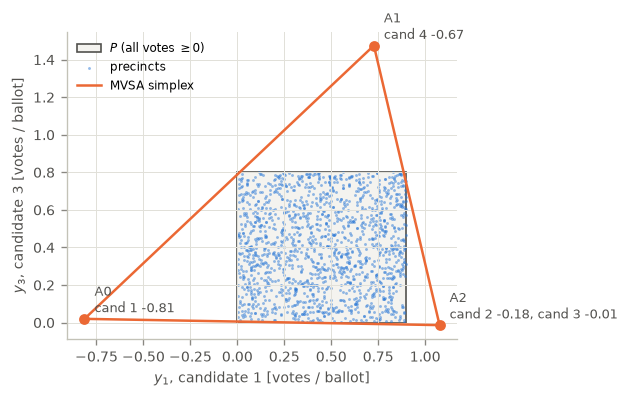

In [5]:
c = CASES["C5"]
M_hat = c["M_hat"]
tri = np.vstack([M_hat[[0, 2]].T, M_hat[[0, 2]].T[:1]])   # (y1, y3) of each vertex, closed
fig, ax = plt.subplots(figsize=(4.2, 3.8))
ax.add_patch(plt.Rectangle((0, 0), 0.9, 0.8, facecolor="#f4f3ef", edgecolor=INK2,
                           lw=1, zorder=0, label="$P$ (all votes $\\geq 0$)"))
idx = rng.choice(n, 1500, replace=False)
ax.scatter(c["Y"][0, idx], c["Y"][2, idx], s=3, color=CAT[0], alpha=0.5, lw=0,
           zorder=1, label="precincts")
ax.plot(tri[:, 0], tri[:, 1], color=CAT[1], lw=1.5, zorder=2, label="MVSA simplex")
ax.scatter(tri[:-1, 0], tri[:-1, 1], s=30, color=CAT[1], zorder=3)
for i, (u, v) in enumerate(tri[:-1]):
    neg = [f"{lab} {val:.2f}" for lab, val in zip(["cand 1", "cand 2", "cand 3", "cand 4"],
                                                   M_hat[:4, i]) if val < 0]
    ax.annotate(f"A{i}" + ("\n" + ", ".join(neg) if neg else ""), (u, v), (6, 4),
                textcoords="offset points", fontsize=7.5, color=INK2)
ax.set(xlabel="$y_1$, candidate 1 [votes / ballot]", ylabel="$y_3$, candidate 3 [votes / ballot]",
       aspect="equal")
ax.legend(loc="upper left", fontsize=7)
plt.show()

### C3: the width archetype

In C3, ballot width varies independently of the political mix. The fit spends
one archetype on width, and that archetype overshoots below zero names per
ballot (Proposition 3, equation 7). Its abundance tracks the width of the
precinct.

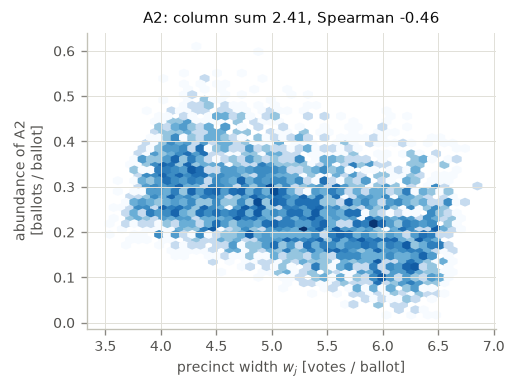

In [6]:
c = CASES["C3"]
k = int(np.argmin(c["M_hat"].sum(axis=0)))
w = c["Y"].sum(axis=0)
fig, ax = plt.subplots(figsize=(4.4, 3.2))
ax.hexbin(w, c["S_hat"][k], gridsize=45, bins="log", cmap="Blues", mincnt=1)
ax.set(xlabel="precinct width $w_j$ [votes / ballot]",
       ylabel=f"abundance of A{k}\n[ballots / ballot]",
       title=f"A{k}: column sum {c['M_hat'][:, k].sum():.2f}, "
             f"Spearman {spearmanr(c['S_hat'][k], w)[0]:.2f}")
plt.show()

### What the toy cases show

Seeded, so these numbers repeat on every run.

- **C0, control:** no negative loadings, and the archetypes recover the three
  types (same column sums, in another order).
- **C1, noise:** 13 small negative loadings, down to $-0.10$. All are on
  candidates whose true loading is 0.05.
- **C2, proportional undervoting:** the extra archetype sits at the blank ballot.
  Its column sum is $-0.34$ and its loadings lie between $-0.04$ and 0, i.e. the
  origin plus noise, as Proposition 6 predicts.
- **C3, width independent of mix:** the width archetype overshoots to a column
  sum of $-1.05$ names per ballot, with loadings down to $-0.32$.
  - No precinct is more than 0.41 of it (extrapolation factor 2.4).
  - Its abundance tracks width (Spearman $-1.00$).
  - The slates come out slightly above their true widths (7.07 / 6.37 / 6.82 vs
    6.95 / 6.55 / 6.00).
- **C4, more types than archetypes:** negative loadings down to $-0.37$, on
  candidates 2, 3 and 8, which the fourth type favors and the fitted archetype
  is pushed away from (the example under Proposition 2).
- **C5, two independent choices:** negatives of $-0.81$, $-0.68$ and $-0.18$ are
  forced (Corollary 5). Each corner of the triangle lies outside the
  nonnegative rectangle.

| signature | likely mechanism |
|---|---|
| a few small negatives on candidates with near-zero support | noise |
| an archetype near the origin, column sum $\approx 0$ | proportional undervoting (harmless: a blank ballot) |
| column sum well below 0; abundance tracks width; no precinct close to pure; slates above their true width | ballot width independent of the political mix |
| large negatives on the candidates one other group supports, column sum $> 0$ | more types than archetypes, or independent choices |

## 4. The NMF basis, and what "mixing" means

NMF gives the same affine-basis reading (1), with every loading
$[\mathbf M]_{\ell i} \ge 0$. There are no correction terms in (3): each
archetype present adds votes for every candidate it loads, and none subtracts.
The hypothesis to test is that forcing everything into the positive space makes
precincts look **more mixed**, or **less contrasted**. Those are different
quantities, and they behave differently:

- **mixing of a precinct's abundances**: purity $\max_k [\mathbf S]_{kj}$ and
  normalized entropy $-\sum_k s_k \log s_k / \log p$;
- **contrast between precincts' abundances**: total-variation distance
  $\tfrac12 \lVert \mathbf s_j - \mathbf s_{j'} \rVert_1$ [ballots/ballot];
- **contrast between precincts' votes**: the distance between reconstructed
  precincts, $\lVert \hat{\mathbf y}_j - \hat{\mathbf y}_{j'} \rVert_2$
  [votes/ballot], compared with the same distance in the data;
- **distinctness of the archetypes**: the distance between loading vectors,
  $\lVert \hat{\mathbf m}_i - \hat{\mathbf m}_{i'} \rVert_2$ [votes/ballot], or
  the site's scale-free cosine distance
  $\tfrac12 (1 - \cos\angle(\hat{\mathbf m}_i, \hat{\mathbf m}_{i'}))$.

**Proposition 7 (pushing the vertices out blurs every precinct the same way).**
Let simplex $\Sigma_1 \subseteq \Sigma_2$ both contain a set of precincts, with
archetypes $\mathbf M_1 = \mathbf M_2 \mathbf C$ for some $\mathbf C \succeq 0$
with $\mathbf 1_p^\top \mathbf C = \mathbf 1_p^\top$ (each vertex of $\Sigma_1$
is a mixture of the vertices of $\Sigma_2$). Then every precinct's coordinates
satisfy $\mathbf s^{(2)}_j = \mathbf C\, \mathbf s^{(1)}_j$, and

$$
\tfrac12 \lVert \mathbf s^{(2)}_j - \mathbf s^{(2)}_{j'} \rVert_1 \;\le\; \tau(\mathbf C)\;
\tfrac12 \lVert \mathbf s^{(1)}_j - \mathbf s^{(1)}_{j'} \rVert_1,
\qquad
\tau(\mathbf C) = \max_{i, i'} \tfrac12 \lVert \mathbf c_i - \mathbf c_{i'} \rVert_1 \le 1,
$$

$$
\max_k [\mathbf s^{(2)}_j]_k \;\le\; \max_{k, i}\, [\mathbf C]_{ki} .
$$

The same $\mathbf C$ also pulls the inner archetypes together:

$$
\underbrace{\lVert \mathbf m^{(1)}_i - \mathbf m^{(1)}_{i'} \rVert_2}_{\text{votes/ballot}}
\;\le\; \tfrac12 \lVert \mathbf c_i - \mathbf c_{i'} \rVert_1\,
\underbrace{\operatorname{diam}(\Sigma_2)}_{\text{votes/ballot}}
\;\le\; \tau(\mathbf C)\, \operatorname{diam}(\Sigma_2),
$$

so in particular $\operatorname{diam}(\Sigma_1) \le \tau(\mathbf C)\,\operatorname{diam}(\Sigma_2)$.

*Proof.* $\mathbf y_j = \mathbf M_1 \mathbf s^{(1)}_j = \mathbf M_2 (\mathbf C \mathbf s^{(1)}_j)$,
and $\mathbf C \mathbf s^{(1)}_j \in \Delta_p$. Coordinates are unique (Section 1),
so $\mathbf s^{(2)}_j = \mathbf C \mathbf s^{(1)}_j$. For the contraction, let
$\mathbf x = \mathbf s^{(1)}_j - \mathbf s^{(1)}_{j'}$, so
$\mathbf 1^\top \mathbf x = 0$. Write $\mathbf x = m(\mathbf a - \mathbf b)$
with $m = \tfrac12 \lVert \mathbf x \rVert_1$ and $\mathbf a, \mathbf b \in \Delta_p$
(the normalized positive and negative parts). Then
$\tfrac12 \lVert \mathbf C \mathbf x \rVert_1 = m \cdot \tfrac12 \lVert \mathbf C\mathbf a - \mathbf C\mathbf b \rVert_1 \le m\, \tau(\mathbf C)$,
because $\mathbf C\mathbf a$ and $\mathbf C\mathbf b$ are mixtures of the columns
of $\mathbf C$ and $\tfrac12\lVert\cdot\rVert_1$ is convex. For purity,
$[\mathbf C \mathbf s]_k = \sum_i [\mathbf C]_{ki} s_i \le \max_i [\mathbf C]_{ki}$.
For the archetypes, $\mathbf m^{(1)}_i - \mathbf m^{(1)}_{i'} = \mathbf M_2(\mathbf c_i - \mathbf c_{i'})$.
Split $\mathbf c_i - \mathbf c_{i'} = m(\mathbf a - \mathbf b)$ as above, with
$m = \tfrac12 \lVert \mathbf c_i - \mathbf c_{i'} \rVert_1$. Then
$\mathbf M_2 \mathbf a$ and $\mathbf M_2 \mathbf b$ are points of $\Sigma_2$, at
most $\operatorname{diam}(\Sigma_2)$ apart. $\square$

**Where the mixing goes.** The two fits reconstruct the same precincts:

$$
\mathbf Y = \mathbf M_1 \mathbf S_1 = \mathbf M_2 \mathbf S_2,
\qquad \mathbf M_1 = \mathbf M_2\, \mathbf C, \qquad \mathbf S_2 = \mathbf C\, \mathbf S_1 .
$$

The column-stochastic $\mathbf C$ sits in the *archetypes* of the inner fit and
in the *abundances* of the outer fit. The more $\mathbf C$ mixes (the smaller
$\tau(\mathbf C)$), the closer together the inner archetypes and the more
blurred the outer abundances, by the same factor. Neither fit is "less mixed"
overall: the outer one shows distinct archetypes and blended precincts, the
inner one blended archetypes and purer precincts.

MVSA's overshoot past the data (Lemma 4), which is where its negative loadings
come from, makes it the outer fit. So the **freedom to go negative** puts the
mixing in the abundances, and a fit that stays inside the data (as NMF tends
to) puts it in the archetypes.

**Proposition 8 (a nonnegative simplex that cannot enclose the data).**
Suppose the archetypes are nonnegative and some precincts lie outside
$\Sigma = \operatorname{conv}(\mathbf M)$. When the data press against zero
(Corollary 5), this is unavoidable for every nonnegative fit. SUNSAL's fit
$\hat{\mathbf y}_j = \mathbf M \hat{\mathbf s}_j$ minimizes
$\lVert \mathbf y_j - \mathbf M \mathbf s \rVert_2$ over $\mathbf s \in \Delta_p$,
i.e. it is the Euclidean projection $\Pi_\Sigma(\mathbf y_j)$. Then:

1. $\lVert \hat{\mathbf y}_j - \hat{\mathbf y}_{j'} \rVert_2 \le \lVert \mathbf y_j - \mathbf y_{j'} \rVert_2$:
   reconstructed precincts are pulled together, and the part of their
   difference that points out of $\Sigma$ goes into the residual;
2. every precinct outside $\Sigma$ is mapped to the boundary of $\Sigma$, so its
   abundance vector has at least one zero. Its abundances become *sparser*, not
   more mixed.

*Proof.* (1) Projection onto a closed convex set is non-expansive. (2) The
projection of a point outside a closed convex set lies on its boundary, and a
boundary point of a simplex has a zero barycentric coordinate. $\square$

**Remark 9 (the pipeline's NMF rescaling).** `src.unmixing.nmf` rescales every
NMF archetype to the data's mean column sum $\bar c$ before SUNSAL. With the
sum-to-one constraint, every reconstruction then has the same width,
$\mathbf 1_L^\top \hat{\mathbf y}_j = \bar c$. Under per-ballot normalization the
NMF fit cannot represent ballot width at all, and width differences go entirely
into the residual (notebook 13, Section 5: 32-44% of NMF's squared error). Under
vote-sum every width is 1, so the rescaling costs nothing.

**So, for the hypothesis:**
- *Abundances: more mixed under NMF?* Expected the other way round. Positivity
  keeps NMF's vertices inside the nonnegative region, where they cannot
  overshoot the data. MVSA's overshoot blurs abundances (Proposition 7), while
  NMF's projection sparsifies them (Proposition 8.2).
- *Archetypes: more mixed under NMF?* Expected yes, whenever NMF's simplex sits
  inside MVSA's. Each NMF archetype is then a blend of MVSA's, and they are
  closer together by the same $\tau(\mathbf C)$ that blurs MVSA's abundances
  (Proposition 7, last inequality). This is the sense in which the intuition
  holds.
- *Votes: less contrast under NMF?* Yes, but only where positivity prevents
  enclosing the data (Proposition 8.1) and, per ballot, through the width
  (Remark 9).

The toy cases test this under both normalizations. Vote-sum isolates
nonnegativity from the width effect.

In [7]:
NMF_PARAMS = {"init": "random", "beta_loss": "kullback-leibler", "solver": "mu",
              "max_iter": 1000, "tol": 1e-4}   # the configs' [unmixing] nmf_* values
PAIRS = rng.integers(0, n, (2, 3000))          # random precinct pairs for the contrasts


def nmf_fit(Y, p, seeds=5):
    """Best-of-seeds pipeline NMF (rescaled columns) + SUNSAL: (rmse, M_hat, S_hat)."""
    best = None
    for seed in range(seeds):
        M_hat = extract_endmembers(Y, p, seed, "nmf", NMF_PARAMS)
        S_hat, _, _ = sunsal_mod(M_hat, Y, positivity="yes", addone="yes",
                                 AL_iters=2000, tol=1e-7)
        rmse = np.sqrt(np.mean((Y - M_hat @ S_hat) ** 2))
        if best is None or rmse < best[0]:
            best = (rmse, M_hat, S_hat)
    return best


def pair_dists(M):
    """Euclidean distances between every pair of archetypes (columns of M)."""
    i, k = np.triu_indices(M.shape[1], 1)
    return np.linalg.norm(M[:, i] - M[:, k], axis=0)


def cos_dists(M):
    """The site's cosine distance (1 - cos) / 2 between every pair of archetypes."""
    U = M / np.linalg.norm(M, axis=0)
    i, k = np.triu_indices(M.shape[1], 1)
    return (1 - (U.T @ U)[i, k]) / 2


def mixing(Y, M, S, pairs=PAIRS):
    """Purity, entropy and abundance TV contrast of S; vote contrast of M S vs Y;
    archetype distinctness of M (min pairwise distance relative to the mean
    distance between data precincts, and min cosine distance)."""
    R = M @ S
    Sc = np.clip(S, 1e-12, 1)
    data_dist = np.linalg.norm(Y[:, pairs[0]] - Y[:, pairs[1]], axis=0).mean()
    return {
        "purity": S.max(axis=0).mean(),
        "entropy": (-(Sc * np.log(Sc)).sum(axis=0) / np.log(S.shape[0])).mean(),
        "abundance TV": 0.5 * np.abs(S[:, pairs[0]] - S[:, pairs[1]]).sum(axis=0).mean(),
        "vote contrast / data": (np.linalg.norm(R[:, pairs[0]] - R[:, pairs[1]], axis=0).mean()
                                 / data_dist),
        "archetype min dist / data": pair_dists(M).min() / data_dist,
        "archetype min cos dist": cos_dists(M).min(),
        "RMSE": np.sqrt(np.mean((Y - R) ** 2)),
    }


rows, TOY_FITS = [], {}
for key, c in CASES.items():
    for norm, Y in (("per ballot", c["Y"]), ("per vote", c["Y"] / c["Y"].sum(axis=0))):
        fits = {"MVSA": (c["M_hat"], c["S_hat"]) if norm == "per ballot"
                else mvsa_fit(Y, c["p"])[1:],
                "NMF": nmf_fit(Y, c["p"])[1:]}
        for meth, (M_hat, S_hat) in fits.items():
            rows.append({"case": key, "normalization": norm, "method": meth,
                         "min loading": M_hat.min(), **mixing(Y, M_hat, S_hat)})
            TOY_FITS[(norm, key, meth)] = (M_hat, S_hat)
mix = pd.DataFrame(rows).set_index(["normalization", "case", "method"]).sort_index()
mix.round(3)

min loading  purity  entropy  abundance TV  \
normalization case method                                               
per ballot    C0   MVSA          0.005   0.675    0.676         0.463   
                   NMF           0.005   0.687    0.627         0.456   
              C1   MVSA         -0.097   0.609    0.792         0.379   
                   NMF           0.000   0.670    0.655         0.432   
              C2   MVSA         -0.042   0.514    0.790         0.401   
                   NMF           0.000   0.597    0.656         0.458   
              C3   MVSA         -0.457   0.375    0.940         0.226   
                   NMF           0.022   0.431    0.869         0.311   
              C4   MVSA         -0.367   0.538    0.863         0.304   
                   NMF           0.000   0.639    0.697         0.424   
              C5   MVSA         -0.814   0.527    0.854         0.278   
                   NMF           0.000   0.634    0.672         0.437   
per vote      C0   MVSA         -0.002   0.684    0.668         0.447   
                   NMF           0.004   0.707    0.610         0.482   
              C1   MVSA         -0.023   0.625    0.769         0.361   
                   NMF           0.000   0.681    0.662         0.447   
              C2   MVSA         -0.227   0.451    0.890         0.294   
                   NMF           0.000   0.604    0.693         0.461   
              C3   MVSA         -0.043   0.372    0.946         0.204   
                   NMF           0.004   0.432    0.867         0.313   
              C4   MVSA         -0.073   0.567    0.825         0.331   
                   NMF           0.000   0.680    0.654         0.412   
              C5   MVSA         -0.198   0.527    0.854         0.278   
                   NMF           0.000   0.634    0.672         0.437   

                           vote contrast / data  archetype min dist / data  \
normalization case method                                                    
per ballot    C0   MVSA                   0.990                      2.039   
                   NMF                    0.873                      1.937   
              C1   MVSA                   0.901                      2.189   
                   NMF                    0.796                      1.834   
              C2   MVSA                   0.990                      1.828   
                   NMF                    0.757                      0.726   
              C3   MVSA                   0.975                      3.797   
                   NMF                    0.729                      1.837   
              C4   MVSA                   0.829                      2.678   
                   NMF                    0.746                      1.801   
              C5   MVSA                   1.000                      3.406   
                   NMF                    0.862                      2.034   
per vote      C0   MVSA                   0.990                      2.151   
                   NMF                    0.988                      2.017   
              C1   MVSA                   0.898                      2.342   
                   NMF                    0.894                      1.945   
              C2   MVSA                   0.983                      0.915   
                   NMF                    0.980                      1.931   
              C3   MVSA                   0.959                      2.079   
                   NMF                    0.952                      2.426   
              C4   MVSA                   0.831                      2.575   
                   NMF                    0.801                      1.910   
              C5   MVSA                   1.000                      3.406   
                   NMF                    0.862                      2.034   

                           archetype min cos dist   RMSE  
normalization case method               

In [8]:
# NMF minus MVSA, per case: positive purity / TV = NMF abundances less mixed;
# negative vote contrast = NMF pulls precincts' votes together; negative archetype
# distances = NMF archetypes closer together
diff = (mix.xs("NMF", level="method") - mix.xs("MVSA", level="method"))[
    ["purity", "entropy", "abundance TV", "vote contrast / data",
     "archetype min dist / data", "archetype min cos dist", "RMSE"]]
diff.round(3)

purity  entropy  abundance TV  vote contrast / data  \
normalization case                                                        
per ballot    C0     0.013   -0.048        -0.008                -0.117   
              C1     0.062   -0.137         0.053                -0.105   
              C2     0.083   -0.135         0.057                -0.233   
              C3     0.056   -0.071         0.085                -0.246   
              C4     0.101   -0.167         0.120                -0.083   
              C5     0.106   -0.182         0.158                -0.138   
per vote      C0     0.023   -0.058         0.036                -0.001   
              C1     0.056   -0.107         0.086                -0.004   
              C2     0.153   -0.197         0.167                -0.003   
              C3     0.060   -0.079         0.109                -0.007   
              C4     0.113   -0.171         0.080                -0.030   
              C5     0.106   -0.182         0.158                -0.138   

                    archetype min dist / data  archetype min cos dist   RMSE  
normalization case                                                            
per ballot    C0                       -0.102                  -0.011  0.059  
              C1                       -0.355                  -0.082  0.033  
              C2                       -1.102                  -0.275  0.066  
              C3                       -1.960                  -0.140  0.048  
              C4                       -0.877                  -0.065  0.015  
              C5                       -1.372                  -0.158  0.038  
per vote      C0                       -0.134                  -0.024  0.000  
              C1                       -0.397                  -0.075  0.000  
              C2                        1.016                   0.217  0.000  
              C3                        0.346                   0.029  0.000  
              C4                       -0.665                  -0.097  0.001  
              C5                       -1.372                  -0.158  0.009

In [9]:
def blend_matrix(M_out, M_in):
    """C with 1ᵀC = 1ᵀ minimizing ‖M_out C − M_in‖_F: each inner archetype in the
    affine coordinates of the outer ones (Proposition 7). Nothing forces C ⪰ 0;
    a nonnegative C means the inner simplex sits inside the outer one."""
    p_out, p_in = M_out.shape[1], M_in.shape[1]
    lam = 1e3 * np.abs(M_out).max()   # heavy weight = sum-to-one as a hard constraint
    return np.linalg.lstsq(np.vstack([M_out, lam * np.ones((1, p_out))]),
                           np.vstack([M_in, lam * np.ones((1, p_in))]), rcond=None)[0]


def tau(C):
    """Dobrushin coefficient: the largest TV distance between two columns of C."""
    return max(0.5 * np.abs(C[:, i] - C[:, k]).sum()
               for i in range(C.shape[1]) for k in range(i + 1, C.shape[1]))


def blend_summary(M_mvsa, M_nmf):
    C = blend_matrix(M_mvsa, M_nmf)
    return {
        "blend fit error": np.linalg.norm(M_mvsa @ C - M_nmf) / np.linalg.norm(M_nmf),
        "min C": C.min(),
        "own share": C.max(axis=0).mean(),   # weight on each NMF archetype's main MVSA parent
        "tau(C)": tau(C),
        "diam NMF / diam MVSA": pair_dists(M_nmf).max() / pair_dists(M_mvsa).max(),
    }


# Is each NMF archetype a blend of MVSA's (C ⪰ 0), and are they pulled together
# by no more than tau(C)?
def frame(rows, names):
    """DataFrame from {tuple key: {column: value}} with a named MultiIndex."""
    return pd.DataFrame(list(rows.values()),
                        index=pd.MultiIndex.from_tuples(list(rows), names=names))


toy_blend = frame({
    (norm, key): blend_summary(TOY_FITS[(norm, key, "MVSA")][0], TOY_FITS[(norm, key, "NMF")][0])
    for (norm, key, meth) in TOY_FITS if meth == "MVSA"}, ["normalization", "case"])
toy_blend.sort_index().round(3)

blend fit error  min C  own share  tau(C)  \
normalization case                                              
per ballot    C0              0.273 -0.094      0.925   1.105   
              C1              0.291 -0.105      0.861   1.057   
              C2              0.108 -0.090      0.725   1.129   
              C3              0.057 -0.127      0.587   0.829   
              C4              0.284 -0.051      0.708   0.753   
              C5              0.086 -0.003      0.689   0.668   
per vote      C0              0.001 -0.007      0.949   0.951   
              C1              0.007  0.026      0.864   0.839   
              C2              0.322 -0.167      0.616   0.907   
              C3              0.056 -0.137      0.580   0.997   
              C4              0.164  0.027      0.841   0.901   
              C5              0.086 -0.003      0.689   0.668   

                    diam NMF / diam MVSA  
normalization case                        
per ballot    C0                   0.961  
              C1                   0.821  
              C2                   0.636  
              C3                   0.637  
              C4                   0.692  
              C5                   0.480  
per vote      C0                   0.922  
              C1                   0.780  
              C2                   0.554  
              C3                   0.746  
              C4                   0.691  
              C5                   0.480

### What the toy comparison shows

Per vote isolates nonnegativity: every width is 1, so the NMF rescaling costs
nothing. Read the NMF $-$ MVSA table there first.

- **Abundances are less mixed under NMF, not more.** In all six cases, NMF minus
  MVSA gives purity $+0.02$ to $+0.15$, entropy $-0.06$ to $-0.20$, and
  abundance TV between precincts $+0.04$ to $+0.17$. This holds even where both
  fit the data equally well (C0-C4, same RMSE). MVSA's simplex overshoots,
  including through noise, and the overshoot blurs every precinct toward the
  middle (Proposition 7).
- **Vote contrast is reduced only where positivity blocks an exact fit.** In
  C0-C4, NMF's reconstructions are as spread out as MVSA's (differences of
  $-0.001$ to $-0.03$). In C5, where Corollary 5 forces negative loadings, NMF
  cannot enclose the square: its reconstructions are pulled together ($-0.14$),
  and that contrast goes into the residual (RMSE 0.009 vs 0), as Proposition 8
  says.
- **Per ballot, NMF also loses the width.** Vote contrast drops by $0.08$-$0.25$
  and RMSE rises by $0.015$-$0.066$ in every case, the control included (Remark
  9). The abundances still come out less mixed than MVSA's in all cases but one
  (C0, TV $-0.008$).
- **The archetypes are closer together under NMF.** NMF's simplex has the
  smaller diameter in every case, at 0.48-0.96 of MVSA's under both
  normalizations. The minimum cosine distance between archetypes is also
  smaller, except per vote in C2 and C3, where MVSA itself returns two
  near-duplicate archetypes (0.03 and 0.04).
- **Proposition 7's assumption holds only in the cleaner toys.** Per vote in
  C0, C1, C4 and C5, the NMF archetypes are blends of MVSA's: the blend fit error
  is at most 0.16 and the smallest entry of $\mathbf C$ is at least $-0.01$.
  Elsewhere, NMF's simplex pokes out of MVSA's ($\min \mathbf C$ from $-0.05$ to
  $-0.17$), and the proposition applies only roughly. Per ballot, $\tau(\mathbf C)$
  can exceed 1, where the bound says nothing.

So nonnegativity does not mix the abundances; it mixes the archetypes. It
*reduces contrast in the votes* where the data press against zero, and per
ballot it erases ballot width. Precincts looking mixed and alike is MVSA's
doing, through the overshoot that also creates its negative loadings.
Archetypes looking alike is NMF's.

## 5. The real archetypes

The MVSA sweep at $p = 4$ (the site's default), for every run the site shows:
per ballot for 2019-2025 and per vote for all five years. For each archetype:

- **column sum** $c_k$: names per ballot under per-ballot normalization, always
  1 under vote-sum;
- **negative loadings**: count below $-0.01$ and the most negative candidates;
- **partner**: the other archetype that gives the most support to the
  candidates $k$ is negative on (support weighted by how negative $k$ is). This
  is the "pushed away from type $b$" reading of Proposition 2;
- **largest precinct abundance** in the sweep's reference trial, and the
  extrapolation factor $1/\max$;
- **Spearman correlation with width**, per ballot only (under vote-sum every
  precinct's width is 1).

The **label** applies the signature table from Section 3:
- *width overshoot*: per ballot, $c_k < 0$, Spearman $< -0.7$;
- *noise-sized*: most negative loading above $-0.05$;
- *contrast*: anything else with negative loadings;
- *none*: no negative loadings.

Under per-ballot normalization, an archetype with $c_k > 12$ is also flagged:
it marks more names than any ballot can hold, i.e. it overshoots upward
(mechanism (b)).

Needs the sweeps run with the current configs (2026-11-09 normalization change)
and their local `abundances_ref.parquet` files. Run time: about a minute.

In [10]:
from src.config import load_config, set_normalization
from src.data import load_complete
from src.data.loading import load_sweep
from src.data.preprocessing import preprocess_from_config

P_REAL = 4
MAX_NAMES = 12  # senatorial seats: a ballot can mark at most 12 names
RUNS = [(y, "ballot") for y in ("2019", "2022", "2025")] + \
       [(y, "vote_sum") for y in ("2013", "2016", "2019", "2022", "2025")]


def short(label):
    return label.split(",")[0].title()


rows = []
for year, norm in RUNS:
    cfg = load_config(f"../configs/config_{year}.ini")
    if norm == "vote_sum":
        set_normalization(cfg, "vote_sum")
    sweep = load_sweep(cfg, full_resolution=True)[P_REAL]
    M_df = sweep["loadings_mean"]
    A = sweep["abundances_ref"][[f"arch_{k}" for k in range(P_REAL)]].to_numpy().T
    pre = preprocess_from_config(load_complete(cfg), cfg, verbose=False)
    assert list(pre.candidate_labels) == list(M_df.index)
    w = pre.Y.sum(axis=0)
    M = M_df.to_numpy()
    names = [short(c) for c in M_df.index]
    for k in range(P_REAL):
        m = M[:, k]
        neg = np.flatnonzero(m < -0.01)
        others = [r for r in range(P_REAL) if r != k]
        partner = (max(others, key=lambda r: float((M[neg, r] * -m[neg]).sum()))
                   if len(neg) else None)
        rho = spearmanr(A[k], w)[0] if norm == "ballot" else np.nan
        csum = m.sum()
        if not len(neg):
            label = "none"
        elif norm == "ballot" and csum < 0 and rho < -0.7:
            label = "width overshoot"
        elif m.min() > -0.05:
            label = "noise-sized"
        else:
            label = f"contrast vs A{partner}"
        rows.append({
            "year": year, "normalization": "per ballot" if norm == "ballot" else "per vote",
            "archetype": f"A{k}",
            "top positive": " / ".join(names[i] for i in np.argsort(-m)[:3]),
            "column sum": csum,
            "above 12 names": bool(norm == "ballot" and csum > MAX_NAMES),
            "# negative": len(neg),
            "min loading": m.min(),
            "most negative": ", ".join(f"{names[i]} {m[i]:.2f}"
                                       for i in neg[np.argsort(m[neg])][:3]),
            "partner": f"A{partner}" if partner is not None else "",
            "max abundance": A[k].max(),
            "extrapolation 1/max": 1 / A[k].max(),
            "Spearman(s_k, width)": rho,
            "label": label,
        })
real = pd.DataFrame(rows).set_index(["normalization", "year", "archetype"])
real.round(2)

top positive  column sum  \
normalization year archetype                                                 
per ballot    2019 A0               Dela Rosa / Go / Tolentino       13.23   
                   A1            Marcos / Bong Revilla / Lapid       13.50   
                   A2                     Aquino / Poe / Roxas       12.66   
                   A3             Gutoc / Bong Revilla / Roxas       -8.99   
              2022 A0                 Teodoro / Roque / Villar       11.31   
                   A1              Legarda / Estrada / Padilla       16.94   
                   A2            Hontiveros / Diokno / De Lima        7.35   
                   A3         Padilla / Del Rosario / Pimentel       -4.54   
              2025 A0            Aquino / Pangilinan / Mendoza       12.87   
                   A1           Marcos / Abalos / Bong Revilla       16.96   
                   A2                  Dela Rosa / Go / Bondoc       11.60   
                   A3             Lapid / Revillame / Pacquiao       -8.26   
per vote      2013 A0               Zubiri / Pimentel / Gordon        1.00   
                   A1          Aquino / Magsaysay / Hontiveros        1.00   
                   A2             Gordon / Honasan / Trillanes        1.00   
                   A3                 Binay / Enrile / Legarda        1.00   
              2016 A0              Sotto / Villanueva / Lacson        1.00   
                   A1              Zubiri / Tolentino / Osmeña        1.00   
                   A2               Drilon / De Lima / Petilla        1.00   
                   A3           Romualdez / Petilla / Pacquiao        1.00   
              2019 A0             Gutoc / Mangudadatu / Aquino        1.00   
                   A1             Go / Mangudadatu / Dela Rosa        1.00   
                   A2           Bong Revilla / Lapid / Estrada        1.00   
                   A3                     Poe / Ong / Cayetano        1.00   
              2022 A0                Padilla / Tulfo / Estrada        1.00   
                   A1                Padilla / Zubiri / Balita        1.00   
                   A2           Hontiveros / Diokno / Escudero        1.00   
                   A3                 Teodoro / Roque / Villar        1.00   
              2025 A0            Aquino / Pangilinan / Mendoza        1.00   
                   A1                  Dela Rosa / Go / Bondoc        1.00   
                   A2              Marcos / Abalos / Tolentino        1.00   
                   A3                 Lapid / Tulfo / Pacquiao        1.00   

                              above 12 names  # negative  min loading  \
normalization year archetype                                            
per ballot    2019 A0                   True           9        -0.40   
                   A1                   True           9        -0.79   
                   A2                   True           8        -0.51   
                   A3                  False          26        -0.78   
              2022 A0                  False           7        -0.40   
                   A1                   True           6        -0.28   
                   A2                  False          15        -0.82   
                   A3                  False          27        -0.43   
              2025 A0                   True           7        -0.20   
                   A1                   True          19        -0.27   
                   A2                  False          24        -0.25   
                   A3                  False          37        -0.67   
per vote      2013 A0                  False           8        -0.13   
                   A1                  False           6        -0.18   
                   A2                  False           7        -0.41   
                   A3                  False           6        -0.18   
              2016 A0                  False          10        -0.23   
          

In [11]:
# Counts of each label per run
real.groupby(["normalization", "year"])["label"].value_counts().unstack(fill_value=0)

label               contrast vs A0  contrast vs A1  contrast vs A2  \
normalization year                                                   
per ballot    2019               1               1               1   
              2022               0               1               2   
              2025               0               2               1   
per vote      2013               2               0               2   
              2016               1               1               1   
              2019               1               0               0   
              2022               0               2               1   
              2025               1               1               0   

label               contrast vs A3  noise-sized  width overshoot  
normalization year                                                
per ballot    2019               0            0                1  
              2022               0            0                1  
              2025               0            0                1  
per vote      2013               0            0                0  
              2016               1            0                0  
              2019               3            0                0  
              2022               1            0                0  
              2025               1            1                0

### What the real archetypes show (MVSA, $p = 4$)

- **Per ballot, every year has exactly one width-overshoot archetype**: A3 in
  2019, 2022 and 2025.
  - Column sums are $-8.99$, $-4.54$ and $-8.26$ names per ballot.
  - Spearman correlation with width is $-0.90$, $-0.95$ and $-0.96$.
  - No precinct is more than 0.55, 0.59 or 0.52 of it.

  The slates overshoot the other way. In 2019 all three, in 2022 one and in
  2025 two have column sums above the 12-name maximum, up to 16.96 names per
  ballot. Overshooting at both ends is the prism signature (Section 2 (b), toy
  C3): ballot width varies largely independently of the political mix. Under
  actual voters, 2025's width archetype is $-8.26$, against $-18.42$ under the
  old valid-ballot denominator (notebook 13).
- **The other per-ballot negatives are contrasts**, named by their partner. A
  few examples:
  - 2019 A1 (Marcos / Bong Revilla / Lapid) is negative on Gutoc, Diokno and
    Alejano, which A2 (Aquino / Poe / Roxas) carries.
  - 2022 A2 (Hontiveros / Diokno / De Lima) is negative on Padilla, Estrada and
    Roque, which A1 carries.
  - 2025 A2 (Dela Rosa / Go / Bondoc) is negative on Tulfo, Abalos and Sotto,
    which A1 (Marcos / Abalos / Bong Revilla) carries.
- **Per vote, the width archetype disappears in every year**, and the negatives
  shrink. The most negative loadings are $-0.41$, $-0.23$, $-0.36$, $-0.36$ and
  $-0.21$ (2013 to 2025), and 2025's A3 is noise-sized ($-0.05$). What remains
  are contrasts, from more types than archetypes or from independent choices
  (Section 2 (a), (c)). Two examples:
  - 2019 A3 (Poe / Ong / Cayetano) is negative on Gutoc and Mangudadatu, which
    A0 carries.
  - 2022 A2 is negative on Padilla, which A1 carries.

Proposition 3 holds for exact fits. With residuals, SUNSAL can still give a
precinct an abundance near 1 in an archetype with negative loadings (2016 per
vote A0: 1.00; 2019 A0: 0.93; 2025 A2: 0.94). Such precincts sit beyond that
vertex and are not reconstructed exactly.

### MVSA vs NMF on the real data

The same mixing and contrast measures as in Section 4, at $p = 4$ for every run.
Abundances are refit with SUNSAL to each method's trial-mean loadings, so the
two methods are compared on the same footing.

In [12]:
mix_rows = []
pairs_real, REAL_FITS = {}, {}
for year, norm in RUNS:
    cfg = load_config(f"../configs/config_{year}.ini")
    if norm == "vote_sum":
        set_normalization(cfg, "vote_sum")
    Y = preprocess_from_config(load_complete(cfg), cfg, verbose=False).Y
    pr = np.random.default_rng(0).integers(0, Y.shape[1], (2, 3000))
    norm_label = "per ballot" if norm == "ballot" else "per vote"
    pairs_real[(norm_label, year)] = pr
    for meth in ("mvsa", "nmf"):
        sweep = load_sweep(cfg, method=meth).get(P_REAL)
        if sweep is None:
            continue
        M_hat = sweep["loadings_mean"].to_numpy()
        S_hat, _, _ = sunsal_mod(M_hat, Y, positivity="yes", addone="yes",
                                 AL_iters=1000, tol=1e-4)
        REAL_FITS[(norm_label, year, meth.upper())] = (M_hat, S_hat, sweep["loadings_mean"])
        mix_rows.append({"normalization": norm_label,
                         "year": year, "method": meth.upper(),
                         "min loading": M_hat.min(), **mixing(Y, M_hat, S_hat, pr)})
real_mix = pd.DataFrame(mix_rows).set_index(["normalization", "year", "method"]).sort_index()
real_mix.round(3)

min loading  purity  entropy  abundance TV  \
normalization year method                                               
per ballot    2019 MVSA         -0.792   0.339    0.970         0.149   
                   NMF           0.000   0.499    0.782         0.387   
              2022 MVSA         -0.816   0.358    0.961         0.162   
                   NMF           0.002   0.482    0.805         0.356   
              2025 MVSA         -0.668   0.376    0.956         0.174   
                   NMF           0.000   0.522    0.781         0.395   
per vote      2013 MVSA         -0.407   0.295    0.993         0.057   
                   NMF           0.006   0.454    0.850         0.312   
              2016 MVSA         -0.229   0.394    0.908         0.068   
                   NMF           0.001   0.511    0.770         0.364   
              2019 MVSA         -0.362   0.354    0.959         0.100   
                   NMF           0.000   0.533    0.730         0.388   
              2022 MVSA         -0.364   0.352    0.956         0.104   
                   NMF           0.000   0.487    0.818         0.322   
              2025 MVSA         -0.208   0.343    0.974         0.141   
                   NMF           0.000   0.535    0.770         0.413   

                           vote contrast / data  archetype min dist / data  \
normalization year method                                                    
per ballot    2019 MVSA                   0.823                      5.583   
                   NMF                    0.591                      1.372   
              2022 MVSA                   0.769                      4.818   
                   NMF                    0.521                      1.385   
              2025 MVSA                   0.852                      4.605   
                   NMF                    0.741                      1.548   
per vote      2013 MVSA                   0.679                     13.041   
                   NMF                    0.646                      1.995   
              2016 MVSA                   0.603                      9.775   
                   NMF                    0.578                      1.410   
              2019 MVSA                   0.725                      7.762   
                   NMF                    0.680                      1.493   
              2022 MVSA                   0.697                      6.049   
                   NMF                    0.672                      1.500   
              2025 MVSA                   0.839                      5.606   
                   NMF                    0.819                      1.682   

                           archetype min cos dist   RMSE  
normalization year method                                 
per ballot    2019 MVSA                     0.280  0.059  
                   NMF                      0.113  0.086  
              2022 MVSA                     0.205  0.059  
                   NMF                      0.094  0.080  
              2025 MVSA                     0.394  0.052  
                   NMF                      0.184  0.064  
per vote      2013 MVSA                     0.474  0.010  
                   NMF                      0.084  0.010  
              2016 MVSA                     0.405  0.009  
                   NMF                      0.062  0.009  
              2019 MVSA                     0.416  0.010  
                   NMF                      0.111  0.011  
              2022 MVSA                     0.284  0.009  
                   NMF                      0.105  0.009  
              2025 MVSA                     0.459  0.007  
                   NMF                      0.183  0.007

### What the MVSA vs NMF comparison shows

Same pattern as the toys (Section 4), and larger.

- **NMF abundances are purer in every run.** Purity is 0.45-0.54 for NMF
  vs 0.30-0.39 for MVSA, and entropy 0.73-0.85 vs 0.91-0.99. MVSA puts
  precincts 2.2-5.5 times closer together in abundance: TV distance 0.06-0.17
  vs 0.31-0.41. The gap is largest in 2013 and 2016 (5.5 and 5.4 times), where
  MVSA precincts are almost indistinguishable (TV 0.06-0.07).
- **NMF archetypes are closer together in every run.** The minimum cosine
  distance between archetypes is 0.06-0.18 for NMF vs 0.21-0.47 for MVSA. The
  closest pair is 1.4-2.0 times the mean distance between precincts for NMF,
  and 4.6-13.0 times for MVSA. The next subsection shows the two facts are the
  same fact.
- **Per vote, where nonnegativity is isolated**, NMF fits as well as MVSA (RMSE
  0.007-0.011 for both). Its reconstructions are only slightly less spread out
  (vote contrast lower by 0.02-0.05), so where the real data press against zero
  the cost is small.
- **Per ballot**, NMF's vote contrast is lower by 0.11-0.25 and its RMSE higher
  by 0.012-0.027. That is the width it cannot represent (Remark 9), the same
  width that MVSA's overshoot archetype carries.

### Where the mixing goes: NMF archetypes as blends of MVSA's

Proposition 7 says the mixing doesn't disappear when abundances get purer: if
NMF's simplex sits inside MVSA's, then $\hat{\mathbf M}_{\text{NMF}} =
\hat{\mathbf M}_{\text{MVSA}} \mathbf C$ with $\mathbf C$ column-stochastic. The
NMF archetypes are then blends of MVSA's and closer together, and MVSA's
abundances are NMF's blurred by the same $\mathbf C$. To test this, fit
$\mathbf C$ for every run without requiring $\mathbf C \succeq 0$ (only
$\mathbf 1^\top \mathbf C = \mathbf 1^\top$), and check:

- **blend fit error**: $\lVert \hat{\mathbf M}_{\text{MVSA}} \mathbf C -
  \hat{\mathbf M}_{\text{NMF}} \rVert_F / \lVert \hat{\mathbf M}_{\text{NMF}}
  \rVert_F$, how well the NMF archetypes lie in MVSA's affine span;
- **min C**: whether $\mathbf C \succeq 0$, i.e. whether the NMF archetypes are
  genuine blends (inside MVSA's simplex), not just affine combinations;
- **own share**: the weight each NMF archetype puts on its main MVSA parent;
- **diam NMF / diam MVSA** against **tau(C)**, the bound in Proposition 7;
- the minimum distance between archetypes, Euclidean (ratio) and cosine (the
  site's scale);
- **abundance TV** between precincts: MVSA's, NMF's blurred by $\mathbf C$, and
  NMF's. If Proposition 7 holds, the first two should be close.

In [13]:
blend_rows = {}
for norm_label, year in pairs_real:
    if (norm_label, year, "NMF") not in REAL_FITS:
        continue
    M_m, S_m, _ = REAL_FITS[(norm_label, year, "MVSA")]
    M_n, S_n, _ = REAL_FITS[(norm_label, year, "NMF")]
    C = blend_matrix(M_m, M_n)
    pr = pairs_real[(norm_label, year)]

    def tv(S):
        return 0.5 * np.abs(S[:, pr[0]] - S[:, pr[1]]).sum(axis=0).mean()

    blend_rows[(norm_label, year)] = {
        **blend_summary(M_m, M_n),
        "min dist NMF / MVSA": pair_dists(M_n).min() / pair_dists(M_m).min(),
        "min cos dist MVSA": cos_dists(M_m).min(),
        "min cos dist NMF": cos_dists(M_n).min(),
        "abundance TV MVSA": tv(S_m),
        "abundance TV C S_NMF": tv(C @ S_n),
        "abundance TV NMF": tv(S_n),
    }
real_blend = frame(blend_rows, ["normalization", "year"])
real_blend.sort_index().round(2)

blend fit error  min C  own share  tau(C)  \
normalization year                                              
per ballot    2019             0.22   0.05       0.40    0.42   
              2022             0.26   0.06       0.43    0.45   
              2025             0.28   0.10       0.46    0.41   
per vote      2013             0.08   0.13       0.36    0.23   
              2016             0.13   0.03       0.40    0.40   
              2019             0.20   0.06       0.42    0.36   
              2022             0.11   0.07       0.46    0.50   
              2025             0.09   0.11       0.47    0.45   

                    diam NMF / diam MVSA  min dist NMF / MVSA  \
normalization year                                              
per ballot    2019                  0.34                 0.25   
              2022                  0.35                 0.29   
              2025                  0.34                 0.34   
per vote      2013                  0.16                 0.15   
              2016                  0.22                 0.14   
              2019                  0.23                 0.19   
              2022                  0.26                 0.25   
              2025                  0.28                 0.30   

                    min cos dist MVSA  min cos dist NMF  abundance TV MVSA  \
normalization year                                                           
per ballot    2019               0.28              0.11               0.15   
              2022               0.21              0.09               0.16   
              2025               0.39              0.18               0.17   
per vote      2013               0.47              0.08               0.06   
              2016               0.41              0.06               0.07   
              2019               0.42              0.11               0.10   
              2022               0.28              0.11               0.10   
              2025               0.46              0.18               0.14   

                    abundance TV C S_NMF  abundance TV NMF  
normalization year                                          
per ballot    2019                  0.09              0.39  
              2022                  0.09              0.36  
              2025                  0.13              0.39  
per vote      2013                  0.05              0.31  
              2016                  0.06              0.36  
              2019                  0.09              0.39  
              2022                  0.10              0.32  
              2025                  0.14              0.41

In [14]:
# One blend matrix in full: 2025 per vote. Rows are MVSA archetypes, columns NMF
# archetypes, each named by its top two candidates; every column sums to 1.
def top2(M_df, k):
    return " / ".join(short(c) for c in M_df.iloc[:, k].sort_values(ascending=False).index[:2])


M_m, _, df_m = REAL_FITS[("per vote", "2025", "MVSA")]
M_n, _, df_n = REAL_FITS[("per vote", "2025", "NMF")]
C = blend_matrix(M_m, M_n)
pd.DataFrame(C, index=[f"MVSA A{k}: {top2(df_m, k)}" for k in range(P_REAL)],
             columns=[f"NMF A{k}: {top2(df_n, k)}" for k in range(P_REAL)]).round(2)

,NMF A0: Dela Rosa / Go,NMF A1: Marcos / Abalos,NMF A2: Aquino / Pangilinan,NMF A3: Lapid / Tulfo
MVSA A0: Aquino / Pangilinan,0.20,0.15,0.44,0.23
MVSA A1: Dela Rosa / Go,0.52,0.12,0.20,0.16
MVSA A2: Marcos / Abalos,0.14,0.43,0.25,0.12
MVSA A3: Lapid / Tulfo,0.14,0.30,0.11,0.50


### Archetypes across $p$

The site's comparison tab shows the other side of this. NMF archetypes change
little from one $p$ to the next, and their minimum distance is low from $p = 2$
on. Two numbers per run and method:

- **matched cosine across $p$**: cosine similarity of each archetype at $p$ to
  its Hungarian match at $p + 1$ (the lineage network's matched links, over the
  sweep's trial-mean loadings);
- **min cosine distance between one run's archetypes** at $p = 2$, $4$ and $12$,
  from the committed `data/distinctness/` files (one run at the config seed,
  notebook 08).

In [15]:
import json

from src.unmixing.matching import archetype_lineage

stab = {}
for year, norm in RUNS:
    cfg = load_config(f"../configs/config_{year}.ini")
    if norm == "vote_sum":
        set_normalization(cfg, "vote_sum")
    norm_label = "per ballot" if norm == "ballot" else "per vote"
    for meth in ("mvsa", "nmf"):
        sweep = load_sweep(cfg, method=meth)
        if not sweep:
            continue
        edges = archetype_lineage({p: sweep[p]["loadings_mean"].to_numpy() for p in sweep})
        sims = np.array([e["similarity"] for e in edges if not e["split"]])
        sub = ("vote_sum/" if norm == "vote_sum" else "") + ("nmf/" if meth == "nmf" else "")
        dj = json.load(open(f"../data/distinctness/{sub}{year}.json"))
        mins = {p: dj["distinct"][str(p)]["cos"]["min"] for p in dj["ps"]}
        stab[(norm_label, year, meth.upper())] = {
            "matched cos across p: median": np.median(sims),
            "matched cos across p: min": sims.min(),
            "min cos dist p=2": mins[2],
            "min cos dist p=4": mins[4],
            "min cos dist p=12": mins[12],
        }
stability = frame(stab, ["normalization", "year", "method"])
stability.sort_index().round(2)

matched cos across p: median  \
normalization year method                                 
per ballot    2019 MVSA                            0.88   
                   NMF                             0.97   
              2022 MVSA                            0.92   
                   NMF                             0.98   
              2025 MVSA                            0.90   
                   NMF                             0.99   
per vote      2013 MVSA                            0.89   
                   NMF                             0.98   
              2016 MVSA                            0.89   
                   NMF                             0.98   
              2019 MVSA                            0.95   
                   NMF                             0.98   
              2022 MVSA                            0.95   
                   NMF                             0.99   
              2025 MVSA                            0.95   
                   NMF                             0.99   

                           matched cos across p: min  min cos dist p=2  \
normalization year method                                                
per ballot    2019 MVSA                         0.49              0.42   
                   NMF                          0.91              0.13   
              2022 MVSA                         0.67              0.39   
                   NMF                          0.95              0.14   
              2025 MVSA                         0.63              0.65   
                   NMF                          0.91              0.28   
per vote      2013 MVSA                         0.64              0.56   
                   NMF                          0.93              0.08   
              2016 MVSA                         0.55              0.62   
                   NMF                          0.92              0.08   
              2019 MVSA                         0.55              0.59   
                   NMF                          0.93              0.14   
              2022 MVSA                         0.57              0.58   
                   NMF                          0.89              0.15   
              2025 MVSA                         0.65              0.64   
                   NMF                          0.88              0.28   

                           min cos dist p=4  min cos dist p=12  
normalization year method                                       
per ballot    2019 MVSA                0.24               0.13  
                   NMF                 0.11               0.15  
              2022 MVSA                0.21               0.31  
                   NMF                 0.09               0.18  
              2025 MVSA                0.42               0.05  
                   NMF                 0.20               0.16  
per vote      2013 MVSA                0.48               0.40  
                   NMF                 0.15               0.18  
              2016 MVSA                0.42               0.37  
                   NMF                 0.08               0.15  
              2019 MVSA                0.41               0.30  
                   NMF                 0.12               0.13  
              2022 MVSA                0.20               0.27  
                   NMF                 0.12               0.18  
              2025 MVSA                0.45               0.32  
                   NMF                 0.19               0.17

### What the blend analysis shows

- **Every NMF archetype is a blend of MVSA's.** $\mathbf C$ has no negative
  entry in any run (smallest 0.03-0.13), though the fit does not require it.
  So NMF's simplex sits inside MVSA's, as Proposition 7 assumes. On average each
  NMF archetype puts 0.36-0.47 on its main MVSA parent and spreads the rest over
  the others. Per vote, the NMF archetypes lie close to MVSA's span (fit error
  0.08-0.20). Per ballot they lie less close (0.22-0.28), because NMF's
  rescaling removes the width (Remark 9).
- **The archetypes contract within the bound.** NMF's diameter is 0.16-0.35 of
  MVSA's, below $\tau(\mathbf C) = 0.23$-$0.50$ in every run. The closest pair
  contracts about as much (0.14-0.34).
- **The same $\mathbf C$ accounts for MVSA's mixed abundances.** Blurring
  NMF's abundances by $\mathbf C$ takes the TV distance between precincts from
  0.31-0.41 down to 0.05-0.14. Per vote, this is within 0.01 of MVSA's own
  0.06-0.14. Per ballot it falls short (0.09-0.13 vs 0.15-0.17), where the
  blend fits worse.
- **Example, 2025 per vote.** Each NMF archetype is about half its MVSA
  namesake (0.43-0.52) plus 0.11-0.30 of each of the others. NMF's
  Marcos / Abalos archetype, for instance, is $0.43$ MVSA Marcos / Abalos
  $+\, 0.30$ Lapid / Tulfo $+\, 0.15$ Aquino / Pangilinan $+\, 0.12$
  Dela Rosa / Go.
- **Across $p$, NMF archetypes barely move.** Matched cosine similarity between
  consecutive $p$ has a median of 0.97-0.99 for NMF vs 0.88-0.95 for MVSA. The
  worst match is 0.88-0.95 vs 0.49-0.67. NMF's minimum cosine distance is
  already 0.08-0.28 at $p = 2$, and 0.08-0.20 at $p = 4$ and 0.13-0.18 at
  $p = 12$. MVSA's starts at 0.39-0.65 and falls. So under NMF there is no
  distinctness floor to find. A plausible reason for the stability: NMF's
  vertices sit inside the data, near dense regions, so an added vertex splits
  off part of the cloud and leaves the others near where they were. MVSA's
  vertices are extrapolations set by the most extreme precincts and the shape
  of the whole simplex, so an added vertex moves all of them.

So "more mixed" or "less mixed" is not a property of the electorate. It depends
on where the method puts the mixing. MVSA puts it in the abundances, with
distinct but extrapolated archetypes that are unstable across $p$. NMF puts it
in the archetypes: they are stable blends of MVSA's, and the
precincts are purer coordinates in that blended basis.

## Summary

1. **Reading.** The archetypes are an affine basis and abundances are
   coordinates in it; the loading vectors are not necessarily orthogonal. A
   negative loading is a correction term. Its effect is a contrast with what it
   replaces, its sign is relative to this fit, and no precinct can be purely
   that archetype (Propositions 1-3).
2. **Cause.** Negative loadings appear when the data have more corners than the
   fit has archetypes (Lemma 4). They are forced when the data fill the
   nonnegative part of their plane (Corollary 5). Per ballot, every year's
   mostly-negative archetype is a width overshoot: the prism signature, with
   slates above 12 names per ballot at the other end. The remaining negatives
   are contrasts with a named partner archetype.
3. **NMF.** NMF and MVSA put the mixing in different factors (Proposition 7).
   MVSA's overshoot gives distinct archetypes and blurs every precinct toward
   the middle. NMF's archetypes are blends of MVSA's (a nonnegative,
   column-stochastic $\mathbf C$ in every run), so its precincts look purer
   while its archetypes are closer together and nearly unchanged from one $p$ to
   the next. The "more mixing" intuition holds for the archetypes, not the
   abundances. In the votes, NMF loses a little contrast where the data press
   against zero (Proposition 8), and, per ballot, all of the width (Remark 9).
   Consequence for choosing $p$: the distinctness floor (notebook 08) is an MVSA
   diagnostic. Under NMF the archetypes are close together at every $p$, so the
   floor gives no signal.